<a href="https://www.kaggle.com/code/minhtuan11/it2058-da?scriptVersionId=359270071" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
!pip install -q --upgrade torch torchvision torchaudio torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 3.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 3.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 6.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 9.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 34.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 4.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 108.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 22.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 3.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import random
import numpy as np
import torch
import torch._utils

# Ép gán thuộc tính _utils vào torch
setattr(torch, '_utils', torch._utils)

import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False  

SEED = 42
seed_everything(SEED)

#### SỬ dụng tỉ lệ của tập datashet 50 25 25

In [3]:
import os
import pandas as pd

# Đường dẫn gốc chứa 3 thư mục: train, valid, test
base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

def load_data_from_folder(split_name):
    folder_path = os.path.join(base_dir, split_name)
    filepaths, labels = [], []
    
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepaths.append(os.path.join(root, file))
                labels.append(os.path.basename(root))
                
    return pd.DataFrame({'filepath': filepaths, 'label': labels})

# 1. Đọc trực tiếp từ các thư mục có sẵn
train_df = load_data_from_folder('train')
val_df   = load_data_from_folder('valid')
test_df  = load_data_from_folder('test')

# 2. Gom tất cả nhãn, sắp xếp cố định theo thứ tự bảng chữ cái (tránh lệch idx)
unique_labels = sorted(list(set(train_df['label'].unique()) | 
                            set(val_df['label'].unique()) | 
                            set(test_df['label'].unique())))

label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}

# 👉 3. TẠO TARGET_NAMES VÀ NUM_CLASSES CHO BÁO CÁO & MÔ HÌNH
num_classes = len(label_to_idx)
target_names = [label for label, _ in sorted(label_to_idx.items(), key=lambda x: x[1])]

# 4. Ánh xạ nhãn sang dạng số trên cả 3 tập
train_df['label_idx'] = train_df['label'].map(label_to_idx)
val_df['label_idx']   = val_df['label'].map(label_to_idx)
test_df['label_idx']  = test_df['label'].map(label_to_idx)

# 5. In kiểm tra thông tin xuất ra
print("=== THÔNG TIN DỮ LIỆU ĐÃ CHUẨN HÓA NHÃN ===")
print(f"Danh sách các lớp ({num_classes} lớp): {target_names}")
print(f"Tập Train: {len(train_df)} ảnh")
print(f"Tập Valid: {len(val_df)} ảnh")
print(f"Tập Test:  {len(test_df)} ảnh\n")

# Bảng tổng hợp chi tiết theo từng lớp
split_summary = pd.DataFrame({
    'Train': train_df['label'].value_counts(),
    'Valid': val_df['label'].value_counts(),
    'Test':  test_df['label'].value_counts()
}).fillna(0).astype(int)

print("--- Phân bố mẫu trong các thư mục gốc ---")
print(split_summary)

=== THÔNG TIN DỮ LIỆU ĐÃ CHUẨN HÓA NHÃN ===
Danh sách các lớp (5 lớp): ['Aorta', 'Flows', 'Other', 'V sign', 'X sign']
Tập Train: 3989 ảnh
Tập Valid: 1352 ảnh
Tập Test:  1379 ảnh

--- Phân bố mẫu trong các thư mục gốc ---
        Train  Valid  Test
label                     
Other    1490    628   689
V sign   1049    362   259
Flows     700    175   219
Aorta     490     96   133
X sign    260     91    79


#### Chia theo paper 60 20 20 

In [4]:
# import os
# import re
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import GroupShuffleSplit

# base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

# filepaths, labels, patient_ids = [], [], []

# for root, dirs, files in os.walk(base_dir):
#     for file in files:
#         if file.lower().endswith(('.png', '.jpg', '.jpeg')):
#             full_path = os.path.join(root, file)
            
#             # 1. Lấy tên lớp từ thư mục chứa file
#             label = os.path.basename(root)
            
#             # 2. Tách Mã Bệnh Nhân từ tên file (Ví dụ: "Flows test (137).png" -> "137")
#             match = re.search(r"\((\d+)\)", file)
#             patient_id = match.group(1) if match else os.path.splitext(file)[0]

#             filepaths.append(full_path)
#             labels.append(label)
#             patient_ids.append(patient_id)

# # Tạo DataFrame tổng
# df = pd.DataFrame({
#     'filepath': filepaths, 
#     'label': labels, 
#     'patient_id': patient_ids
# })

# # 3. TẠO CỘT 'label_idx' TRỰC TIẾP TRÊN DF GỐC (Tránh lỗi KeyError)
# unique_labels = sorted(df['label'].unique())
# label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}
# df['label_idx'] = df['label'].map(label_to_idx)

# # 4. TẠO BỘ BIẾN XUẤT RA CHO BLOCK TRAIN
# num_classes = len(label_to_idx)
# target_names = [label for label, _ in sorted(label_to_idx.items(), key=lambda x: x[1])]

# # 5. CHIA TẬP THEO PATIENT-LEVEL (Train 60%, Valid 20%, Test 20%)
# gss_train = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=42)
# train_idx, temp_idx = next(gss_train.split(df, groups=df['patient_id']))

# train_df = df.iloc[train_idx].copy().reset_index(drop=True)
# temp_df  = df.iloc[temp_idx].copy().reset_index(drop=True)

# gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
# val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df['patient_id']))

# val_df  = temp_df.iloc[val_idx].copy().reset_index(drop=True)
# test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)

# print("=== HOÀN TẤT XỬ LÝ DỮ LIỆU (BLOCK 1) ===")
# print(f"Tổng số ảnh: {len(df)}")
# print(f"Danh sách các lớp ({num_classes} lớp): {target_names}")
# print(f"Số lượng bệnh nhân thực tế: {df['patient_id'].nunique()}")
# print(f"Phân bổ: Train={len(train_df)} | Valid={len(val_df)} | Test={len(test_df)} ảnh")
# print(f"Các cột đã sẵn sàng: {list(train_df.columns)}")

In [5]:
!find '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester/test' -type f | wc -l

1380


### Exit early

In [6]:
class ExitHead(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super().__init__()
        # 1. Conv 1x1: Giảm số lượng channel (giảm nhẹ tính toán)
        self.reduce_conv = nn.Conv2d(in_channels, hidden_channels, kernel_size=1)
        
        # 2. GAP (Global Average Pooling): Gom kích thước không gian (Ví dụ 28x28 -> 1x1)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        # 3. LayerNorm: Chuẩn hóa dữ liệu (PyTorch LayerNorm chuộng đầu vào 1D)
        self.norm = nn.LayerNorm(hidden_channels)
        
        # 4. Linear Classifier: Đưa ra xác suất dự đoán (Ví dụ 5 class tim thai nhi)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x):
        # x đầu vào có dạng [Batch, Channels, Height, Width]
        x = self.reduce_conv(x)
        x = self.gap(x)
        
        # Ép phẳng (Flatten) từ [Batch, Channels, 1, 1] thành vector [Batch, Channels]
        x = torch.flatten(x, start_dim=1)
        
        # Đưa qua Norm và Linear
        x = self.norm(x)
        out = self.classifier(x)
        return out

### Multi Exit Convnext

In [7]:

class MultiExitConvNeXt(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # 1. Tải mô hình ConvNeXt-Tiny pre-trained
        backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        features = backbone.features
        
        # ==========================================
        # 2. RÃ MÔ HÌNH THÀNH 3 KHÚC (Slicing)
        # ==========================================
        # Khúc 1: Từ đầu đến hết Stage 2 (Bao gồm index 0, 1, 2, 3)
        self.part1 = features[:4]
        
        # Khúc 2: Downsample + Stage 3 (Index 4, 5)
        self.part2 = features[4:6]
        
        # Khúc 3: Downsample + Stage 4 (Index 6, 7)
        self.part3 = features[6:8]
        
        # ==========================================
        # 3. LẮP RÁP CÁC EXIT HEADS
        # ==========================================
        # Exit 1: Nằm sau Stage 2 (in_channels=192). Nén xuống 64 
        self.exit1 = ExitHead(in_channels=192, hidden_channels=64, num_classes=num_classes)
        
        # Exit 2: Nằm sau Stage 3 (in_channels=384). Nén xuống 128.
        self.exit2 = ExitHead(in_channels=384, hidden_channels=128, num_classes=num_classes)
        
        # Exit 3 (Main): Sửa lại Classifier gốc của ConvNeXt để ra 5 class
        self.avgpool = backbone.avgpool
        self.exit3 = backbone.classifier
        self.exit3[-1] = nn.Linear(768, num_classes) # Thay lớp Linear cuối cùng

    # ==========================================
    # 4. SỬA HÀM FORWARD CHẠY 3 KẾT QUẢ
    # ==========================================
    def forward(self, x):
        # Chạy Khúc 1 (Hết Stage 2)
        x = self.part1(x)
        y1 = self.exit1(x)       # <--- Rẽ nhánh lấy y1
        
        # Chạy tiếp Khúc 2 (Hết Stage 3)
        x = self.part2(x)
        y2 = self.exit2(x)       # <--- Rẽ nhánh lấy y2
        
        # Chạy nốt Khúc 3 (Full model - Hết Stage 4)
        x = self.part3(x)
        x = self.avgpool(x)      # Hàm pool gốc
        y3 = self.exit3(x)       # <--- Kết quả cuối y3
        
        return y1, y2, y3        # Trả về cả 3 logits

In [8]:
### Multi Exit Convnext DRAS

In [9]:
import torch
import torch._utils

# Ép gán thuộc tính _utils vào torch để tránh lỗi AttributeError
setattr(torch, '_utils', torch._utils)

import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

# =============================================================================
# 1. MODULE DUAL-REGION ARTIFACT SUPPRESSION (DRAS) - ĐÃ SỬA GROUPNORM
# =============================================================================
class DRASModule(nn.Module):
    def __init__(self, in_channels, reduction=16, use_prior=True):
        super().__init__()
        self.use_prior = use_prior
        hidden_dim = in_channels // reduction  # 192//16 = 12 kênh, 384//16 = 24 kênh
        
        # Spatial Attention Gate
        self.spatial_gate = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=1),
            nn.GroupNorm(4, hidden_dim),  # 🎯 Đã sửa từ 8 -> 4 (12 và 24 đều chia hết cho 4)
            nn.GELU(),
            nn.Conv2d(hidden_dim, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        B, C, H, W = x.shape
        attn = self.spatial_gate(x)  # Shape: [B, 1, H, W]
        
        if self.use_prior:
            prior_mask = torch.ones((1, 1, H, W), device=x.device, dtype=x.dtype)
            
            # Region 1: Che góc trên-phải (Chữ thông số máy SRI II, PRF...)
            prior_mask[:, :, :int(H * 0.35), int(W * 0.85):] = 0.05
            
            # Region 2: Che góc dưới-trái (Ô Thumbnail)
            prior_mask[:, :, int(H * 0.70):, :int(W * 0.35)] = 0.05
            
            attn = attn * prior_mask
            
        return x * attn


# =============================================================================
# 2. LỚP EXIT HEAD PHỤ (Dùng cho Exit 1 & Exit 2)
# =============================================================================
class ExitHead(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super().__init__()
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, hidden_channels),
            nn.LayerNorm(hidden_channels),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_channels, num_classes)
        )

    def forward(self, x):
        return self.head(x)


# =============================================================================
# 3. MÔ HÌNH MULTI-EXIT CONVNEXT TÍCH HỢP DRAS
# =============================================================================
class MultiExitConvNeXtDRAS(nn.Module):
    def __init__(self, num_classes=5, use_dras_prior=True):
        super().__init__()
        
        # 1. Tải backbone ConvNeXt-Tiny pre-trained
        backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        features = backbone.features

        # 2. Slicing Backbone thành 3 phần
        self.part1 = features[:4]   # Output Channels: 192 (Hết Stage 2)
        self.part2 = features[4:6]  # Output Channels: 384 (Hết Stage 3)
        self.part3 = features[6:8]  # Output Channels: 768 (Hết Stage 4)

        # 3. Chèn Module DRAS vào sau Stage 2 & Stage 3
        self.dras1 = DRASModule(in_channels=192, use_prior=use_dras_prior)
        self.dras2 = DRASModule(in_channels=384, use_prior=use_dras_prior)

        # 4. Lắp ráp 3 Exit Heads
        self.exit1 = ExitHead(in_channels=192, hidden_channels=64, num_classes=num_classes)
        self.exit2 = ExitHead(in_channels=384, hidden_channels=128, num_classes=num_classes)

        # Exit 3 (Main Head)
        self.avgpool = backbone.avgpool
        self.exit3 = backbone.classifier
        self.exit3[-1] = nn.Linear(768, num_classes)

    def forward(self, x):
        # Stage 1 + Stage 2
        x = self.part1(x)
        x = self.dras1(x)        # DRAS dập nhiễu Stage 2
        y1 = self.exit1(x)

        # Stage 3
        x = self.part2(x)
        x = self.dras2(x)        # DRAS dập nhiễu Stage 3
        y2 = self.exit2(x)

        # Stage 4 (Main Head)
        x = self.part3(x)
        x = self.avgpool(x)
        y3 = self.exit3(x)

        return y1, y2, y3

### Test 

In [10]:
# Test khởi tạo mô hình
if __name__ == "__main__":
    model = MultiExitConvNeXtDRAS(num_classes=5)
    dummy_input = torch.randn(2, 3, 224, 224)
    y1, y2, y3 = model(dummy_input)
    
    print("✅ Khởi tạo thành công ConvNeXt-Tiny + DRAS!")
    print(f"Shape Exit 1: {y1.shape}")
    print(f"Shape Exit 2: {y2.shape}")
    print(f"Shape Exit 3: {y3.shape}")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 247MB/s] 


✅ Khởi tạo thành công ConvNeXt-Tiny + DRAS!
Shape Exit 1: torch.Size([2, 5])
Shape Exit 2: torch.Size([2, 5])
Shape Exit 3: torch.Size([2, 5])


## Main

### Xử lí ảnh 

In [11]:
import cv2
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, f1_score
from torchinfo import summary

In [12]:
# import cv2
# import numpy as np

# ### Cắt theo ROI
# def preprocess_ultrasound_image(image_path, 
#                                 top_left_h_ratio=0.40, 
#                                 top_left_w_ratio=0.08,
#                                 pad_x=50,             # 🎯 Nới rộng 50px sang 2 bên từ mép màu sạch
#                                 pad_y=50,             # 🎯 Nới rộng 50px lên/xuống từ mép màu sạch
#                                 max_noise_dist=120):  # 🎯 Ngưỡng khoảng cách tối đa để loại đốm nhiễu (px)
#     """
#     Tiền xử lý ảnh siêu âm thai nhi:
#     - Bắt khối màu Doppler (Đỏ + Xanh dương).
#     - Lọc bỏ 100% đốm màu nằm cách xa cụm tim chính quá max_noise_dist.
#     - Lấy 100% mép màu thực tế của dải tim thai sạch nhiễu -> Nới rộng padding ra xung quanh.
#     """
#     img = cv2.imread(image_path)
#     if img is None:
#         raise ValueError(f"Không thể đọc file: {image_path}")
        
#     H, W, C = img.shape
#     mid_x = W // 2

#     # =========================================================================
#     # 1. NỬA TRÁI: CHE CỘT THANG MÀU GÓC TRÊN TRÁI
#     # =========================================================================
#     left_img = img[:, :mid_x].copy()
#     mask_h = int(H * top_left_h_ratio)
#     mask_w = int(mid_x * top_left_w_ratio)
#     left_img[0:mask_h, 0:mask_w] = 0

#     # =========================================================================
#     # 2. NỬA PHẢI: BẮT MÀU DOPPLER (ĐỎ + XANH DƯƠNG)
#     # =========================================================================
#     right_raw = img[:, mid_x:].copy()
#     hsv_right = cv2.cvtColor(right_raw, cv2.COLOR_BGR2HSV)

#     # Dải màu Doppler Đỏ & Xanh dương
#     lower_red1, upper_red1 = np.array([0, 40, 40]), np.array([15, 255, 255])
#     lower_red2, upper_red2 = np.array([155, 40, 40]), np.array([180, 255, 255])
#     lower_blue, upper_blue = np.array([85, 40, 40]), np.array([140, 255, 255])

#     mask_r1 = cv2.inRange(hsv_right, lower_red1, upper_red1)
#     mask_r2 = cv2.inRange(hsv_right, lower_red2, upper_red2)
#     mask_b  = cv2.inRange(hsv_right, lower_blue, upper_blue)
#     doppler_mask = mask_r1 | mask_r2 | mask_b

#     # Lọc bỏ rác UI ngoài lề trên Mask
#     doppler_mask[:int(H * 0.10), :] = 0
#     doppler_mask[:, int(mid_x * 0.82):] = 0
#     doppler_mask[int(H * 0.70):, :int(mid_x * 0.38)] = 0

#     contours, _ = cv2.findContours(doppler_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     valid_contours = [c for c in contours if cv2.contourArea(c) > 15]

#     right_processed = np.zeros_like(right_raw)

#     # =========================================================================
#     # 3. LỌC ĐỐM NHIỄU XA & MỞ RỘNG TỪ MÉP MÀU CHUẨN
#     # =========================================================================
#     if valid_contours:
#         # A. Tìm khối màu lớn nhất (Cụm tim chính)
#         main_contour = max(valid_contours, key=cv2.contourArea)
#         M = cv2.moments(main_contour)
#         if M["m00"] > 0:
#             cx_main = int(M["m10"] / M["m00"])
#             cy_main = int(M["m01"] / M["m00"])
#         else:
#             pts_m = main_contour[:, 0, :]
#             cx_main, cy_main = int(np.mean(pts_m[:, 0])), int(np.mean(pts_m[:, 1]))

#         # B. 🎯 LỌC BỎ ĐỐM NHIỄU: Chỉ giữ lại các đốm màu nằm gần cụm chính (< max_noise_dist)
#         clean_color_contours = []
#         for c in valid_contours:
#             pts_c = c[:, 0, :]
#             mc_x, mc_y = np.mean(pts_c[:, 0]), np.mean(pts_c[:, 1])
#             dist = np.sqrt((mc_x - cx_main)**2 + (mc_y - cy_main)**2)
            
#             # Nếu đốm màu nằm trong bán kính cho phép -> GIỮ LẠI (Thuộc tim thai)
#             if dist <= max_noise_dist:
#                 clean_color_contours.append(c)

#         if not clean_color_contours:
#             clean_color_contours = [main_contour]

#         # C. LẤY 100% TẮT CẢ PIXEL MÀU SẠCH (CẢ ĐỎ & XANH DƯƠNG)
#         all_clean_pts = np.vstack([c[:, 0, :] for c in clean_color_contours])
#         color_x_min = np.min(all_clean_pts[:, 0])
#         color_x_max = np.max(all_clean_pts[:, 0])
#         color_y_min = np.min(all_clean_pts[:, 1])
#         color_y_max = np.max(all_clean_pts[:, 1])

#         # D. 🎯 MỞ RỘNG PADDING RA NGOÀI TỪ MÁP MÀU SẠCH (PAD_X, PAD_Y)
#         x_min = max(0, color_x_min - pad_x)
#         x_max = min(mid_x, color_x_max + pad_x)
#         y_min = max(0, color_y_min - pad_y)
#         y_max = min(H, color_y_max + pad_y)

#         # Cắt nguyên bản 100% pixel vùng tim thai
#         right_processed[y_min:y_max, x_min:x_max] = right_raw[y_min:y_max, x_min:x_max]

#     else:
#         # Dự phòng cắt chính giữa màn hình nếu ảnh B-mode không có màu
#         center_x, center_y = mid_x // 2, H // 2
#         x_min, x_max = max(0, center_x - 120), min(mid_x, center_x + 120)
#         y_min, y_max = max(0, center_y - 120), min(H, center_y + 120)
#         right_processed[y_min:y_max, x_min:x_max] = right_raw[y_min:y_max, x_min:x_max]

#     # Đè đen bảo vệ dải chữ UI ngoài lề
#     right_processed[:int(H * 0.35), int(mid_x * 0.88):] = 0  # Cột chữ góc trên-phải
#     right_processed[int(H * 0.70):, :int(mid_x * 0.38)] = 0  # Ô Thumbnail góc dưới-trái

#     final_img_bgr = np.hstack((left_img, right_processed))
#     return final_img_bgr

In [13]:
import cv2
import numpy as np

def preprocess_ultrasound_image(image_path, 
                                 top_left_h=0.40,   # Che thang màu góc trên-trái (Nửa trái)
                                 top_left_w=0.08,
                                 top_right_h=0.35,  # Che cột chữ thông số góc trên-phải (Nửa phải)
                                 top_right_w=0.85,
                                 thumb_h=0.70,      # Che ô Thumbnail góc dưới-trái (Nửa phải)
                                 thumb_w=0.35):
    """
    Tiền xử lý siêu âm Full-Frame (Giữ nguyên kích thước ảnh gốc):
    - KHÔNG cắt ROI, giữ nguyên cấu trúc không gian cho DRAS.
    - Chỉ đè đen (0) đúng 3 vùng UI rác cố định trên màn hình máy Voluson.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Không thể đọc file: {image_path}")
        
    processed_img = img.copy()
    H, W, _ = processed_img.shape
    mid_x = W // 2

    # 1. Che dải thang màu (Góc trên-trái, nửa trái ảnh)
    h_tl = int(H * top_left_h)
    w_tl = int(mid_x * top_left_w)
    processed_img[0:h_tl, 0:w_tl] = 0

    # 2. Che cột chữ thông số máy SRI II, PRF... (Góc trên-phải, nửa phải ảnh)
    h_tr = int(H * top_right_h)
    w_tr = mid_x + int(mid_x * top_right_w)
    processed_img[0:h_tr, w_tr:] = 0

    # 3. Che ô Thumbnail (Góc dưới-trái, nửa phải ảnh)
    h_bl = int(H * thumb_h)
    w_bl = mid_x + int(mid_x * thumb_w)
    processed_img[h_bl:, mid_x:w_bl] = 0

    return processed_img

### Test image 

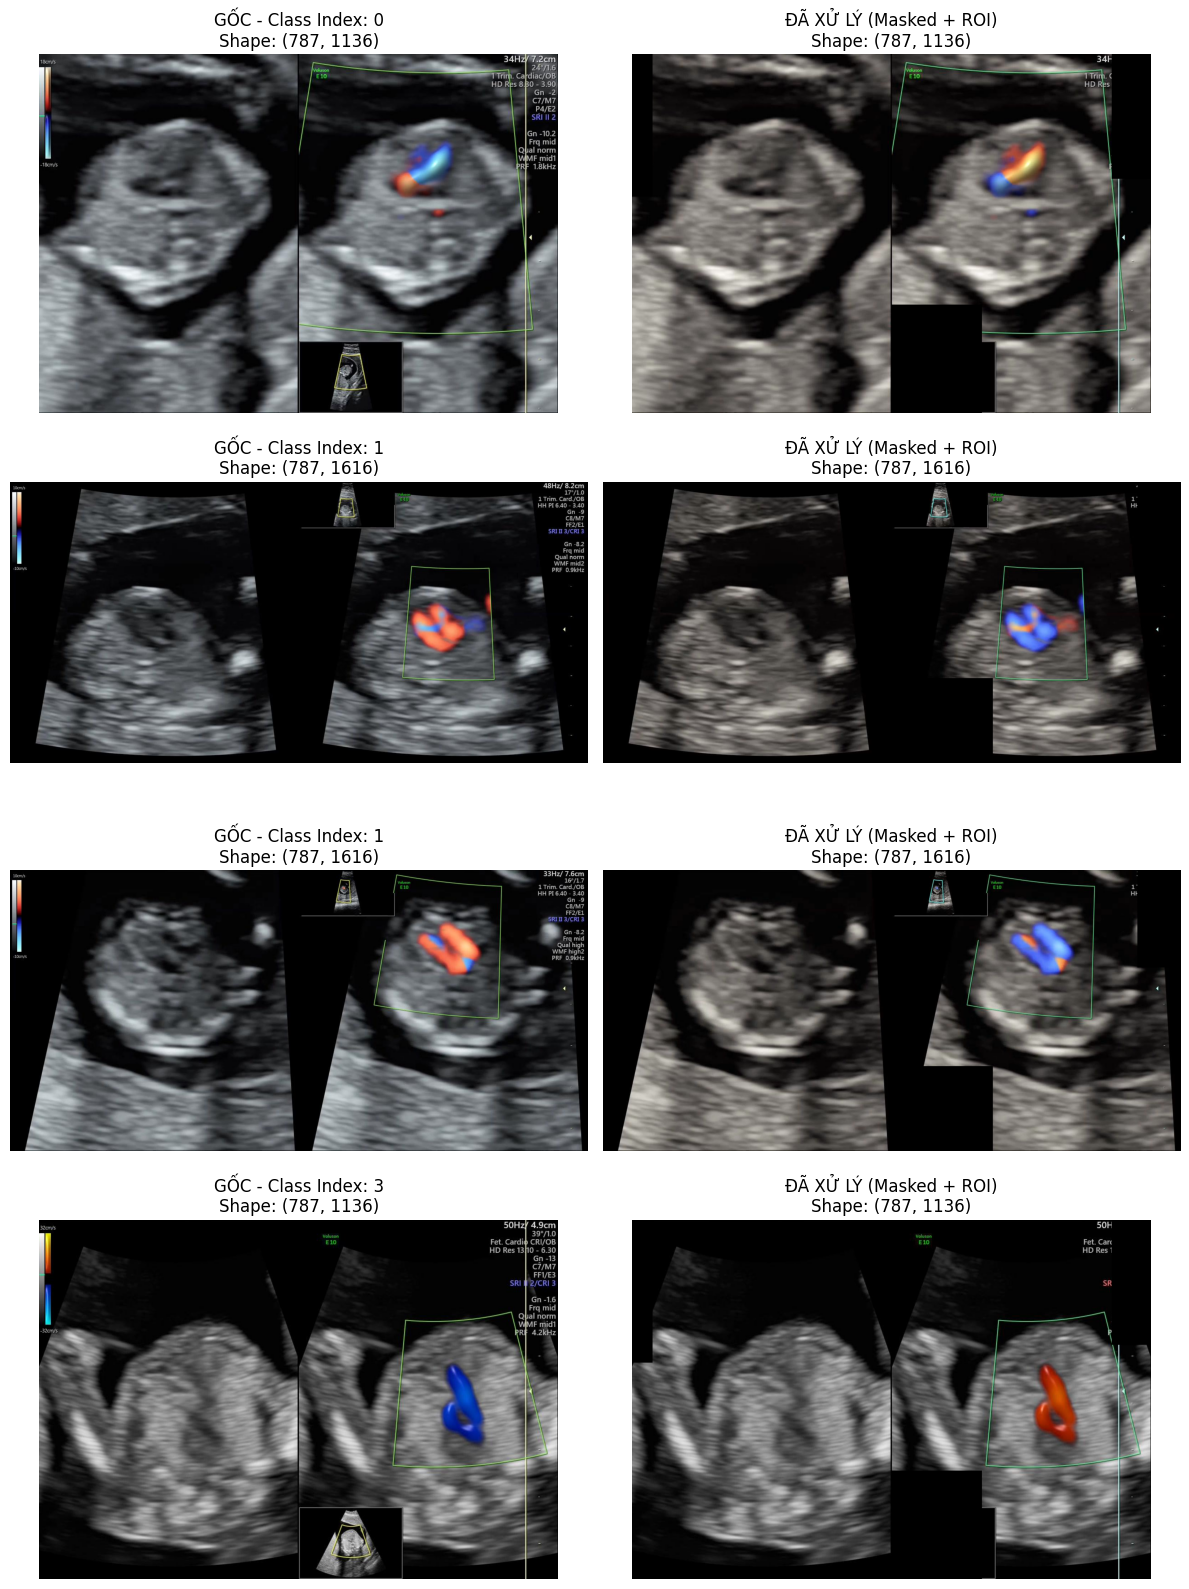

In [14]:
import matplotlib.pyplot as plt
import random

def visualize_preprocessed_samples(df, num_samples=4):
    """
    Hiển thị so sánh ảnh gốc và ảnh sau khi đã Masking & Crop ROI.
    """
    sample_indices = random.sample(range(len(df)), min(num_samples, len(df)))
    
    plt.figure(figsize=(12, 4 * num_samples))
    
    for idx, sample_idx in enumerate(sample_indices):
        img_path = df.loc[sample_idx, 'filepath']
        label = df.loc[sample_idx, 'label_idx']
        
        # 1. Đọc ảnh gốc
        raw_img = cv2.imread(img_path)
        raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        
        # 2. Xử lý qua hàm mới|
        processed_img = preprocess_ultrasound_image(img_path)
        
        # Plot Ảnh Gốc
        plt.subplot(num_samples, 2, idx * 2 + 1)
        plt.imshow(raw_img)
        plt.title(f"GỐC - Class Index: {label}\nShape: {raw_img.shape[:2]}")
        plt.axis('off')
        
        # Plot Ảnh Đã Xử Lý
        plt.subplot(num_samples, 2, idx * 2 + 2)
        plt.imshow(processed_img)
        plt.title(f"ĐÃ XỬ LÝ (Masked + ROI)\nShape: {processed_img.shape[:2]}")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# ==========================================
# GỌI HÀM ĐỂ XEM KẾT QUẢ (Truyền DataFrame của bạn vào đây)
# ==========================================
visualize_preprocessed_samples(train_df, num_samples=4) 
# hoặc:
#visualize_preprocessed_samples(df_test, num_samples=4)

In [15]:
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def visualize_interactive_samples(df, target_names=None):
    """
    Bộ duyệt ảnh tương tác: Xem từng ảnh một bằng nút bấm Next/Prev hoặc Slider.
    """
    total_samples = len(df)
    
    # 1. Khởi tạo các Widget Giao diện
    btn_prev = widgets.Button(description="◀ Trước", button_style='info', icon='arrow-left')
    btn_next = widgets.Button(description="Tiếp ▶", button_style='info', icon='arrow-right')
    slider = widgets.IntSlider(
        value=0, 
        min=0, 
        max=total_samples - 1, 
        step=1, 
        description='Index:', 
        continuous_update=False,
        layout=widgets.Layout(width='50%')
    )
    output = widgets.Output()

    # 2. Hàm vẽ ảnh khi index thay đổi
    def render_image(idx):
        with output:
            clear_output(wait=True)
            
            img_path = df.loc[idx, 'filepath']
            label_idx = df.loc[idx, 'label_idx']
            
            # Lấy tên nhãn dạng chữ
            if 'label' in df.columns:
                label_name = df.loc[idx, 'label']
            elif target_names and label_idx < len(target_names):
                label_name = target_names[label_idx]
            else:
                label_name = f"Class_{label_idx}"
            
            # Đọc & chuyển RGB ảnh gốc
            raw_img = cv2.imread(img_path)
            raw_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
            
            # Tiền xử lý & chuyển RGB cho ảnh hiển thị
            processed_bgr = preprocess_ultrasound_image(img_path)
            processed_rgb = cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB)
            
            # Vẽ hình
            fig, axes = plt.subplots(1, 2, figsize=(13, 6))
            
            # Column 1: Ảnh gốc
            axes[0].imshow(raw_rgb)
            axes[0].set_title(
                f"GỐC - Index [{idx}/{total_samples - 1}]\n"
                f"Lớp: {label_name} (ID: {label_idx}) | Shape: {raw_img.shape[:2]}", 
                fontsize=12, fontweight='bold', color='navy'
            )
            axes[0].axis('off')
            
            # Column 2: Ảnh xử lý
            axes[1].imshow(processed_rgb)
            axes[1].set_title(
                f"ĐÃ XỬ LÝ (Masked + ROI)\n"
                f"Shape: {processed_bgr.shape[:2]}", 
                fontsize=12, fontweight='bold', color='darkgreen'
            )
            axes[1].axis('off')
            
            plt.tight_layout()
            plt.show()

    # 3. Định nghĩa sự kiện bấm nút
    def on_prev_clicked(b):
        if slider.value > 0:
            slider.value -= 1

    def on_next_clicked(b):
        if slider.value < total_samples - 1:
            slider.value += 1

    def on_slider_change(change):
        render_image(change['new'])

    # Gán Event Handlers
    btn_prev.on_click(on_prev_clicked)
    btn_next.on_click(on_next_clicked)
    slider.observe(on_slider_change, names='value')

    # 4. Hiển thị Control Panel & Output
    controls = widgets.HBox([btn_prev, slider, btn_next], layout=widgets.Layout(align_items='center', justify_content='center'))
    display(controls, output)
    
    # Load ảnh đầu tiên
    render_image(0)

# GỌI HÀM DUYỆT ẢNH
visualize_interactive_samples(train_df, target_names=target_names)

Output()

### PyTorch Dataset & DataLoaders

In [16]:
# ==========================================
# PYTORCH DATASET & DATALOADER
# ==========================================
class UltrasoundDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = self.df.loc[idx, 'label_idx']

        # 1. OpenCV Preprocessing (Numpy Array BGR)
        img_bgr = preprocess_ultrasound_image(img_path)

        # 2. Chuyển BGR -> RGB và ép chuẩn PIL Image
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil = Image.fromarray(img_rgb)

        # 3. Transform Pipeline
        if self.transform:
            img_tensor = self.transform(img_pil)
        else:
            img_tensor = transforms.ToTensor()(img_pil)

        return img_tensor, torch.tensor(label, dtype=torch.long)

# Pipeline biến đổi kích thước & chuẩn hóa
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Hàm khởi tạo seed cho từng worker
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)  # SEED đã khai báo

train_loader = DataLoader(
    UltrasoundDataset(train_df, transform_pipeline), 
    batch_size=32, 
    shuffle=True, 
    num_workers=2,
    worker_init_fn=seed_worker,  
    generator=g                
)

val_loader  = DataLoader(UltrasoundDataset(val_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(UltrasoundDataset(test_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)

### Focal Loss & Class Weights  

In [17]:
# ==========================================
# FOCAL LOSS & CLASS WEIGHTS
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label_idx']),
    y=train_df['label_idx'].values
)
alpha = torch.tensor(class_weights, dtype=torch.float)

### Khởi tạo mô hình & Tính toán khối lượng

In [18]:
import torch
from torchinfo import summary  

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang chạy trên thiết bị: {device}\n")

# Khởi tạo mô hình MultiExitConvNeXtDRAS
num_classes = 5
model = MultiExitConvNeXtDRAS(num_classes=num_classes)
model = model.to(device)

print("\n--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---")

# 👉 BẮT BUỘC BỌC print() VÀ TRUYỀN ĐÚNG INPUT SHAPE
print(
    summary(
        model, 
        input_size=(32, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "params_percent", "kernel_size", "mult_adds"],
        row_settings=["var_names"]
    )
)

print("-" * 60 + "\n")

Đang chạy trên thiết bị: cuda


--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---
Layer (type (var_name))                                 Input Shape               Output Shape              Param #                   Param %                   Kernel Shape              Mult-Adds
MultiExitConvNeXtDRAS (MultiExitConvNeXtDRAS)           [32, 3, 224, 224]         [32, 5]                   --                             --                   --                        --
├─Sequential (part1)                                    [32, 3, 224, 224]         [32, 192, 28, 28]         --                             --                   --                        --
│    └─Conv2dNormActivation (0)                         [32, 3, 224, 224]         [32, 96, 56, 56]          --                             --                   --                        --
│    │    └─Conv2d (0)                                  [32, 3, 224, 224]         [32, 96, 56, 56]          4,704                       0.02%      

### Test DataLoader Đơn Luồng

In [19]:
import random
from torch.utils.data import DataLoader

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

# Khởi tạo DataLoader
train_loader = DataLoader(
    UltrasoundDataset(train_df, transform_pipeline), 
    batch_size=32, 
    shuffle=True, 
    num_workers=2,
    worker_init_fn=seed_worker,  
    generator=g                
)
val_loader  = DataLoader(UltrasoundDataset(val_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(UltrasoundDataset(test_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)

# --- KIỂM TRA BATCH ĐẦU TIÊN ---
print("\n🧪 [BATCH TEST] Kiểm tra ghép Batch Tensor...")
try:
    test_imgs, test_lbls = next(iter(train_loader))
    print(f"✅ Batch Images Shape : {test_imgs.shape}") # Phải ra torch.Size([32, 3, 224, 224])
    print(f"✅ Batch Labels Shape : {test_lbls.shape}") # Phải ra torch.Size([32])
    print(f"✅ Data Type           : {test_imgs.dtype}")
except Exception as e:
    print(f"❌ Lỗi ghép Batch: {e}")


🧪 [BATCH TEST] Kiểm tra ghép Batch Tensor...
✅ Batch Images Shape : torch.Size([32, 3, 224, 224])
✅ Batch Labels Shape : torch.Size([32])
✅ Data Type           : torch.float32


### Training

In [20]:
# ==========================================
# CẤU HÌNH LOSS, OPTIMIZER & MẠNG TRAIN
# ==========================================
criterion = FocalLoss(alpha=alpha.to(device), gamma=2)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)

epochs = 15
patience = 4
best_val_f1 = 0.0
best_epoch = 0
early_stop_counter = 0
best_model_wts = copy.deepcopy(model.state_dict())

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}

print(f"{'Epoch':<8} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10} | {'Val Macro F1':<12} | Status")
print("-" * 80)

for epoch in range(epochs):
    # --- TRAINING ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(images)
        
        # --- LƯU Ý KHI DÙNG MULTI-EXIT ---
        # Trường hợp 1: Nếu outputs trả về 1 Tensor duy nhất (Exit cuối)
        if isinstance(outputs, torch.Tensor):
            loss = criterion(outputs, labels)
            preds = outputs
        # Trường hợp 2: Nếu outputs trả về tuple/list các exits (ví dụ: [exit1, exit2, exit_final])
        else:
            loss = sum(criterion(out, labels) for out in outputs) # Cộng tổng loss các exit
            preds = outputs[-1] # Lấy exit cuối cùng để tính accuracy
            
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = preds.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
            
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total
    
    # --- VALIDATION ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            if isinstance(outputs, torch.Tensor):
                loss = criterion(outputs, labels)
                preds = outputs
            else:
                loss = criterion(outputs[-1], labels) # Khi val chỉ tính loss exit cuối
                preds = outputs[-1]
            
            val_loss += loss.item() * images.size(0)
            _, predicted = preds.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total
    val_f1_macro = f1_score(all_labels, all_preds, average='macro')
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(val_f1_macro)
    
    # --- CHECKPOINT & EARLY STOPPING ---
    status = ""
    if val_f1_macro > best_val_f1:
        best_val_f1 = val_f1_macro
        best_epoch = epoch + 1
        best_model_wts = copy.deepcopy(model.state_dict())
        early_stop_counter = 0
        status = "[Saved Best]"
    else:
        early_stop_counter += 1
        status = f"Patience {early_stop_counter}/{patience}"
        
    print(f"{epoch+1:02d}/{epochs:02d}    | {epoch_train_loss:<10.4f} | {epoch_train_acc*100:<9.2f}% | {epoch_val_loss:<10.4f} | {epoch_val_acc*100:<9.2f}% | {val_f1_macro:<12.4f} | {status}")
    
    if early_stop_counter >= patience:
        print(f"\n=> EARLY STOPPING kích hoạt ở Epoch {epoch+1}.")
        break

# Tải lại trọng số tốt nhất
model.load_state_dict(best_model_wts)

Epoch    | Train Loss | Train Acc  | Val Loss   | Val Acc    | Val Macro F1 | Status
--------------------------------------------------------------------------------
01/15    | 2.3153     | 79.99    % | 0.2119     | 74.85    % | 0.7116       | [Saved Best]
02/15    | 1.1906     | 94.91    % | 0.1095     | 88.76    % | 0.8595       | [Saved Best]
03/15    | 0.9422     | 97.54    % | 0.1824     | 87.57    % | 0.8326       | Patience 1/4
04/15    | 0.5277     | 97.87    % | 0.1987     | 88.09    % | 0.8476       | Patience 2/4
05/15    | 0.3528     | 99.07    % | 0.5057     | 88.76    % | 0.8043       | Patience 3/4
06/15    | 0.2335     | 99.42    % | 0.5356     | 87.87    % | 0.8035       | Patience 4/4

=> EARLY STOPPING kích hoạt ở Epoch 6.


<All keys matched successfully>

### Đồ thị 

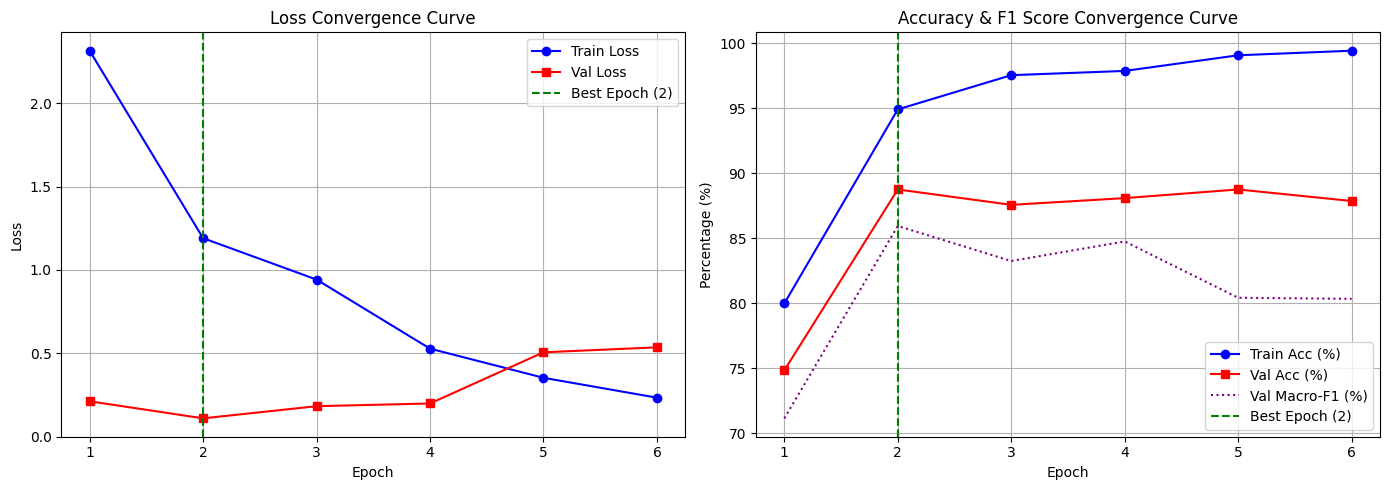

In [21]:
# ==========================================
# VẼ ĐỒ THỊ SỰ HỘI TỤ
# ==========================================
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(history['train_loss'])+1), history['train_loss'], label='Train Loss', color='blue', marker='o')
plt.plot(range(1, len(history['val_loss'])+1), history['val_loss'], label='Val Loss', color='red', marker='s')
plt.axvline(x=best_epoch, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
plt.title('Loss Convergence Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(history['train_acc'])+1), [x*100 for x in history['train_acc']], label='Train Acc (%)', color='blue', marker='o')
plt.plot(range(1, len(history['val_acc'])+1), [x*100 for x in history['val_acc']], label='Val Acc (%)', color='red', marker='s')
plt.plot(range(1, len(history['val_f1'])+1), [x*100 for x in history['val_f1']], label='Val Macro-F1 (%)', color='purple', linestyle=':')
plt.axvline(x=best_epoch, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
plt.title('Accuracy & F1 Score Convergence Curve')
plt.xlabel('Epoch')
plt.ylabel('Percentage (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Đánh giá 

In [22]:
# ==========================================
# ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST
# ==========================================
print("\n" + "="*50)
print(f" THÔNG TIN MÔ HÌNH TỐT NHẤT (Đạt được ở Epoch {best_epoch})")
print("="*50)

model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        
        preds = outputs if isinstance(outputs, torch.Tensor) else outputs[-1]
        
        _, predicted = preds.max(1)
        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.numpy())

                
print("\n[Báo Cáo Chi Tiết Trên Tập Test (Unseen Data)]")
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))


 THÔNG TIN MÔ HÌNH TỐT NHẤT (Đạt được ở Epoch 2)

[Báo Cáo Chi Tiết Trên Tập Test (Unseen Data)]
              precision    recall  f1-score   support

       Aorta     0.7383    0.5940    0.6583       133
       Flows     0.9316    0.9954    0.9625       219
       Other     0.9721    0.8084    0.8827       689
      V sign     0.8194    0.9459    0.8781       259
      X sign     0.4157    0.8734    0.5633        79

    accuracy                         0.8470      1379
   macro avg     0.7754    0.8434    0.7890      1379
weighted avg     0.8826    0.8470    0.8546      1379



In [23]:
# ==========================================================
# SCRIPT ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST
# ==========================================================
import numpy as np
import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score

print("\n" + "="*60, flush=True)
print("  ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST", flush=True)
print("="*60, flush=True)

model.eval()

# 1. Kiểm tra số lượng Exit Head của mô hình
with torch.no_grad():
    sample_img, _ = next(iter(test_loader))
    sample_out = model(sample_img.to(device))
    
    if isinstance(sample_out, (list, tuple)):
        num_exits = len(sample_out)
        print(f"-> Phát hiện mô hình Multi-Exit có tổng cộng {num_exits} Exit Heads.\n", flush=True)
    else:
        num_exits = 1
        print("-> Mô hình chỉ trả về 1 đầu ra duy nhất.\n", flush=True)

if num_exits > 1:
    # Mảng lưu dự đoán riêng cho từng Exit
    all_exit_preds = [[] for _ in range(num_exits)]
    all_test_labels = []

    # 2. Chạy dự đoán trên toàn bộ tập Test
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images) # Trả về list/tuple các Exit
            
            all_test_labels.extend(labels.numpy())
            
            # Thu thập dự đoán của từng Exit Head
            for idx, exit_out in enumerate(outputs):
                _, predicted = exit_out.max(1)
                all_exit_preds[idx].extend(predicted.cpu().numpy())

    # 3. In Bảng So Sánh Tổng Quan
    print(f"{'Exit Head':<12} | {'Accuracy (%)':<15} | {'Macro F1-Score':<15}")
    print("-" * 50, flush=True)

    for idx in range(num_exits):
        acc = accuracy_score(all_test_labels, all_exit_preds[idx]) * 100
        f1 = f1_score(all_test_labels, all_exit_preds[idx], average='macro')
        print(f"Exit {idx+1:<7} | {acc:<15.2f} | {f1:<15.4f}", flush=True)

    print("=" * 50 + "\n", flush=True)

    # 4. In Báo Cáo Chi Tiết Cho Từng Exit Head
    for idx in range(num_exits):
        print(f"\n[BÁO CÁO CHI TIẾT - EXIT HEAD {idx+1}]", flush=True)
        print(classification_report(all_test_labels, all_exit_preds[idx], target_names=target_names, digits=4), flush=True)

else:
    print("Mô hình không phải dạng Multi-Exit, không cần tách đánh giá.")


  ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST
-> Phát hiện mô hình Multi-Exit có tổng cộng 3 Exit Heads.

Exit Head    | Accuracy (%)    | Macro F1-Score 
--------------------------------------------------
Exit 1       | 19.43           | 0.1580         
Exit 2       | 84.34           | 0.7946         
Exit 3       | 84.70           | 0.7890         


[BÁO CÁO CHI TIẾT - EXIT HEAD 1]
              precision    recall  f1-score   support

       Aorta     0.0787    0.2256    0.1167       133
       Flows     0.2246    0.2922    0.2540       219
       Other     0.0000    0.0000    0.0000       689
      V sign     0.2655    0.6602    0.3787       259
      X sign     0.0435    0.0380    0.0405        79

    accuracy                         0.1943      1379
   macro avg     0.1225    0.2432    0.1580      1379
weighted avg     0.0956    0.1943    0.1250      1379


[BÁO CÁO CHI TIẾT - EXIT HEAD 2]
              precision    recall  f1-score   support

       Aorta     0.7109  

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
